In [1]:
import torch
print(torch.__version__)

2.15.0+cpu


In [2]:
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.io import loadmat

# ------------------------------------------------------------------
# Catalogue des fichiers CWRU
# ------------------------------------------------------------------
NORMAL = [97, 98, 99, 100]
PAGES = {
    "12kDE": (12000, {
        ("IR", 7): [105, 106, 107, 108],      ("B", 7): [118, 119, 120, 121],
        ("OR@6", 7): [130, 131, 132, 133],    ("OR@3", 7): [144, 145, 146, 147],
        ("OR@12", 7): [156, 158, 159, 160],
        ("IR", 14): [169, 170, 171, 172],     ("B", 14): [185, 186, 187, 188],
        ("OR@6", 14): [197, 198, 199, 200],
        ("IR", 21): [209, 210, 211, 212],     ("B", 21): [222, 223, 224, 225],
        ("OR@6", 21): [234, 235, 236, 237],   ("OR@3", 21): [246, 247, 248, 249],
        ("OR@12", 21): [258, 259, 260, 261],
        ("IR", 28): [3001, 3002, 3003, 3004], ("B", 28): [3005, 3006, 3007, 3008],
    }),
    "48kDE": (48000, {
        ("IR", 7): [109, 110, 111, 112],      ("B", 7): [122, 123, 124, 125],
        ("OR@6", 7): [135, 136, 137, 138],    ("OR@3", 7): [148, 149, 150, 151],
        ("OR@12", 7): [161, 162, 163, 164],
        ("IR", 14): [174, 175, 176, 177],     ("B", 14): [189, 190, 191, 192],
        ("OR@6", 14): [201, 202, 203, 204],
        ("IR", 21): [213, 214, 215, 217],     ("B", 21): [226, 227, 228, 229],
        ("OR@6", 21): [238, 239, 240, 241],   ("OR@3", 21): [250, 251, 252, 253],
        ("OR@12", 21): [262, 263, 264, 265],
    }),
    "12kFE": (12000, {
        ("IR", 7): [278, 279, 280, 281],      ("B", 7): [282, 283, 284, 285],
        ("OR@6", 7): [294, 295, 296, 297],    ("OR@3", 7): [298, 299, 300, 301],
        ("OR@12", 7): [302, 305, 306, 307],
        ("IR", 14): [274, 275, 276, 277],     ("B", 14): [286, 287, 288, 289],
        ("OR@6", 14): [313, None, None, None], ("OR@3", 14): [310, 309, 311, 312],
        ("IR", 21): [270, 271, 272, 273],     ("B", 21): [290, 291, 292, 293],
        ("OR@6", 21): [315, None, None, None], ("OR@3", 21): [None, 316, 317, 318],
    }),
}
RPM_NOMINAL = {0: 1797, 1: 1772, 2: 1750, 3: 1730}

lignes = []
for charge, num in enumerate(NORMAL):
    lignes.append({"nom": f"Normal_L{charge}", "numero": num, "source": "Normal",
                   "fs": 12000, "defaut": "Sain", "position_OR": None,
                   "diametre_mils": 0, "charge_hp": charge})
for source, (fs, table_page) in PAGES.items():
    for (defaut, diametre), numeros in table_page.items():
        localisation, _, position = defaut.partition("@")
        for charge, num in enumerate(numeros):
            if num is None:
                continue
            nom = (f"{source}_{localisation}{diametre:03d}"
                   + (f"at{position}" if position else "") + f"_L{charge}")
            lignes.append({"nom": nom, "numero": num, "source": source, "fs": fs,
                           "defaut": localisation, "position_OR": position or None,
                           "diametre_mils": diametre, "charge_hp": charge})

catalogue = pd.DataFrame(lignes).set_index("nom")
catalogue["rpm_nominal"] = catalogue["charge_hp"].map(RPM_NOMINAL)

# ------------------------------------------------------------------
# Lecture d'un fichier (téléchargement la 1re fois, puis cache local)
# ------------------------------------------------------------------
URL_CWRU = "https://engineering.case.edu/sites/default/files/"
CACHE = Path("../data/cwru_cache")

def charger(nom):
    info = catalogue.loc[nom]
    numero = int(info["numero"])
    chemin = CACHE / f"{nom}__{numero}.mat"
    if not chemin.exists():
        CACHE.mkdir(parents=True, exist_ok=True)
        for essai in range(1, 4):
            try:
                with urllib.request.urlopen(URL_CWRU + f"{numero}.mat", timeout=60) as reponse:
                    contenu = reponse.read()
                temporaire = chemin.with_suffix(".part")
                temporaire.write_bytes(contenu)
                loadmat(temporaire)
                temporaire.replace(chemin)
                break
            except Exception as erreur:
                print(f"{nom} : tentative {essai} échouée ({type(erreur).__name__})")
                if essai == 3:
                    raise
    mat = loadmat(chemin)

    def choisir(suffixe):
        cles = [k for k in mat if k.endswith(suffixe)]
        bonne = [k for k in cles if k.startswith(f"X{numero:03d}")]
        return (bonne or cles or [None])[0]

    signaux = {"fs": int(info["fs"])}
    for canal in ["DE", "FE", "BA"]:
        cle = choisir(f"_{canal}_time")
        signaux[canal] = None if cle is None else np.ravel(mat[cle])
    cle_rpm = choisir("RPM")
    signaux["rpm"] = float(np.squeeze(mat[cle_rpm])) if cle_rpm else float(info["rpm_nominal"])
    return signaux

# ------------------------------------------------------------------
# Sélection des 40 fichiers (configuration à 10 classes)
# ------------------------------------------------------------------
est_sain_cat = catalogue["source"] == "Normal"
est_12kDE    = catalogue["source"] == "12kDE"
bon_defaut   = catalogue["defaut"].isin(["IR", "B"]) | (catalogue["position_OR"] == "6")
bon_diam     = catalogue["diametre_mils"].isin([7, 14, 21])
selection = catalogue[est_sain_cat | (est_12kDE & bon_defaut & bon_diam)]

ORDRE_LOC = ["Sain", "IR", "B", "OR"]
print(len(catalogue), "fichiers au catalogue,", len(selection), "sélectionnés")

161 fichiers au catalogue, 40 sélectionnés


In [17]:
TAILLE = 2048                                    # points par fenêtre (0,17 s à 12 kHz)

def fenetres_brutes(sel, canal="DE", taille=TAILLE):
    """Découpe chaque fichier en fenêtres de signal brut, normalisées une à une."""
    X, meta = [], []
    for nom, info in sel.iterrows():
        x = charger(nom)[canal]
        n = len(x) // taille
        f = x[:n * taille].reshape(n, taille)
        X.append(f.astype(np.float32))
        meta.append(pd.DataFrame({"fichier": nom, "fenetre": range(n),
                                  "defaut": info["defaut"],
                                  "diametre_mils": info["diametre_mils"],
                                  "charge_hp": info["charge_hp"]}))
    return np.concatenate(X), pd.concat(meta, ignore_index=True)

X, meta = fenetres_brutes(selection)
print(X.shape)

(2953, 2048)


     fichier  fenetre defaut  diametre_mils  charge_hp
0  Normal_L0        0   Sain              0          0
1  Normal_L0        1   Sain              0          0
2  Normal_L0        2   Sain              0          0
3  Normal_L0        3   Sain              0          0
4  Normal_L0        4   Sain              0          0
[ 0.05319692  0.08866154  0.09971815  0.05862092 -0.00458954 -0.056952
 -0.07176369 -0.05862092 -0.04652123 -0.04985908]
0.012 0.072


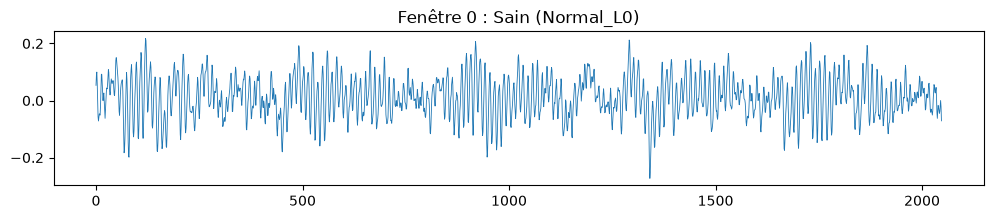

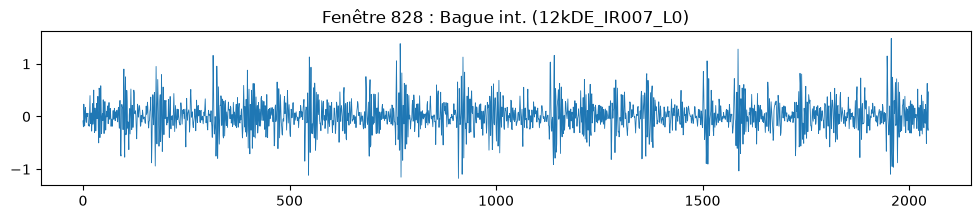

In [6]:
print(meta.head())                       # les 5 premières fenêtres : fichier, défaut, charge…
print(X[0, :10])                         # les 10 premières valeurs de la première fenêtre
print(X[0].mean().round(3), X[0].std().round(3))   # moyenne 0 et écart-type 1

import matplotlib.pyplot as plt
for i, nom in [(0, "Sain"), (meta.index[meta["defaut"] == "IR"][0], "Bague int.")]:
    plt.figure(figsize=(12, 2))
    plt.plot(X[i], lw=0.6)
    plt.title(f"Fenêtre {i} : {nom} ({meta.loc[i, 'fichier']})")
    plt.show()

In [7]:
y = meta["defaut"].map({c: i for i, c in enumerate(ORDRE_LOC)}).to_numpy()
print(ORDRE_LOC)
print(y.shape)                                    # (2953,) : une étiquette par fenêtre
print(meta["defaut"].value_counts())              # nombre de fenêtres par classe
print(pd.crosstab(meta["defaut"], meta["diametre_mils"]))

['Sain', 'IR', 'B', 'OR']
(2953,)
defaut
Sain    828
IR      709
B       708
OR      708
Name: count, dtype: int64
diametre_mils   0    7    14   21
defaut                           
B                0  236  236  236
IR               0  237  236  236
OR               0  236  236  236
Sain           828    0    0    0


In [ ]:
import torch                      # bibliothèque de calcul (tableaux = "tenseurs", gradients automatiques)
from torch import nn              # nn = briques de réseaux de neurones (couches, fonctions de perte)

class CNN1D(nn.Module):           # on définit un modèle ; nn.Module est la classe mère de tout réseau PyTorch
    def __init__(self, n_classes):        # constructeur : on y déclare les couches (une seule fois)
        super().__init__()                # initialise la partie "nn.Module" (obligatoire)

        def bloc(c_in, c_out, k, s=1):    # petite fonction qui fabrique un bloc de 4 opérations
            return nn.Sequential(         # Sequential = les opérations s'enchaînent dans l'ordre
                nn.Conv1d(c_in, c_out, k, stride=s, padding=k // 2),
                    # convolution : c_out filtres de longueur k glissent le long du signal
                    # c_in = nombre de "canaux" en entrée (1 au départ : le signal brut)
                    # stride s = pas du glissement ; padding = zéros ajoutés aux bords
                nn.BatchNorm1d(c_out),    # standardise chaque canal sur le lot (moyenne 0, écart-type 1)
                nn.ReLU(),                # non-linéarité : max(0, x)
                nn.MaxPool1d(2))          # garde le maximum de chaque paire de points : longueur ÷ 2

        self.extracteur = nn.Sequential(  # partie qui extrait des caractéristiques du signal
            bloc(1, 16, 64, 8),           # 1 signal -> 16 filtres de 64 points, pas de 8
            bloc(16, 32, 3),              # 16 -> 32 canaux, filtres courts de 3 points
            bloc(32, 64, 3),              # 32 -> 64 canaux
            bloc(64, 64, 3))              # 64 -> 64 canaux
        self.classifieur = nn.Linear(64, n_classes)   # 64 caractéristiques -> 4 scores (un par classe)

    def forward(self, x):                 # ce que fait le réseau quand on lui donne un lot x
        h = self.extracteur(x.unsqueeze(1))
            # x arrive en (lot, 2048) ; unsqueeze(1) ajoute l'axe "canal" : (lot, 1, 2048)
            # après les 4 blocs : h est de forme (lot, 64, 16)
        return self.classifieur(h.mean(dim=2))
            # moyenne sur l'axe du temps : (lot, 64, 16) -> (lot, 64)
            # puis couche linéaire : (lot, 64) -> (lot, 4) scores

In [9]:
y_loc = meta["defaut"].map({c: i for i, c in enumerate(ORDRE_LOC)}).to_numpy()
est_sain = (meta["defaut"] == "Sain").to_numpy()

lignes = []
preds_graines = []  
for graine in range(3):
    pred = np.full(len(meta), -1)
    for k, d in enumerate([7, 14, 21]):
        en_test = ((~est_sain & (meta["diametre_mils"] == d).to_numpy())
                   | (est_sain & (meta["charge_hp"] == k).to_numpy()))
        modele = entrainer_cnn(X[~en_test], y_loc[~en_test], len(ORDRE_LOC), graine=graine)
        pred[en_test] = predire(modele, X[en_test])
    teste = pred >= 0
    preds_graines.append(pred.copy()) 
    juste = pred[teste] == y_loc[teste]
    ligne = {"Global": 100 * juste.mean()}
    ligne.update({c: 100 * juste[y_loc[teste] == i].mean() for i, c in enumerate(ORDRE_LOC)})
    lignes.append(ligne)
    print(f"Graine {graine} terminée", flush=True)

res_loc = pd.DataFrame(lignes)
resume_loc = pd.DataFrame({"Moyenne (%)": res_loc.mean().round(1),
                           "Écart-type (%)": res_loc.std().round(1)})
resume_loc

Graine 0 terminée
Graine 1 terminée
Graine 2 terminée


,Moyenne (%),Écart-type (%)
Global,72.0,3.6
Sain,100.0,0.0
IR,43.3,8.4
B,99.5,0.4
OR,49.9,20.9


In [10]:
from sklearn.metrics import confusion_matrix

mc = sum(confusion_matrix(y_loc[p >= 0], p[p >= 0], labels=range(len(ORDRE_LOC)))
         for p in preds_graines)
mc = pd.DataFrame(mc, index=ORDRE_LOC, columns=ORDRE_LOC)
mc.index.name = "Réel \\ Prédit"
mc

,Sain,IR,B,OR
Réel \ Prédit,,,,
Sain,1773,0,0,0
IR,0,922,1098,107
B,9,1,2114,0
OR,0,356,708,1060


In [7]:
ORDRE_D = [7, 14, 21]
base = catalogue["defaut"].isin(["IR", "B"]) & catalogue["diametre_mils"].isin(ORDRE_D)
X_de, meta_de = fenetres_brutes(catalogue[base & (catalogue["source"] == "12kDE")], "DE")
X_fe, meta_fe = fenetres_brutes(catalogue[base & (catalogue["source"] == "12kFE")], "FE")
code_d = {d: i for i, d in enumerate(ORDRE_D)}

lignes = []
for loc in ["IR", "B"]:
    app  = (meta_de["defaut"] == loc).to_numpy()
    test = (meta_fe["defaut"] == loc).to_numpy()
    y_app  = meta_de.loc[app, "diametre_mils"].map(code_d).to_numpy()
    y_test = meta_fe.loc[test, "diametre_mils"].map(code_d).to_numpy()
    for graine in range(3):
        modele = entrainer_cnn(X_de[app], y_app, 3, graine=graine)
        juste = predire(modele, X_fe[test]) == y_test
        ligne = {"Localisation": loc, "Exactitude (%)": 100 * juste.mean()}
        ligne.update({f'0,{d:03d}"': 100 * juste[y_test == i].mean()
                      for i, d in enumerate(ORDRE_D)})
        lignes.append(ligne)
    print(f"{loc} terminé", flush=True)

res_fe = pd.DataFrame(lignes)
resume_fe = res_fe.groupby("Localisation").mean().round(1)
resume_fe.insert(1, "Écart-type (%)", res_fe.groupby("Localisation")["Exactitude (%)"].std().round(1))
resume_fe

C:\Users\Admin\AppData\Local\Temp\ipykernel_25356\2139880901.py:25: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  Xt, yt = torch.from_numpy(X_app), torch.from_numpy(y_app)


IR terminé
B terminé


,Exactitude (%),Écart-type (%),"0,007""","0,014""","0,021"""
Localisation,,,,,
B,33.9,0.6,0.3,1.4,100.0
IR,24.9,19.4,27.7,47.0,0.0


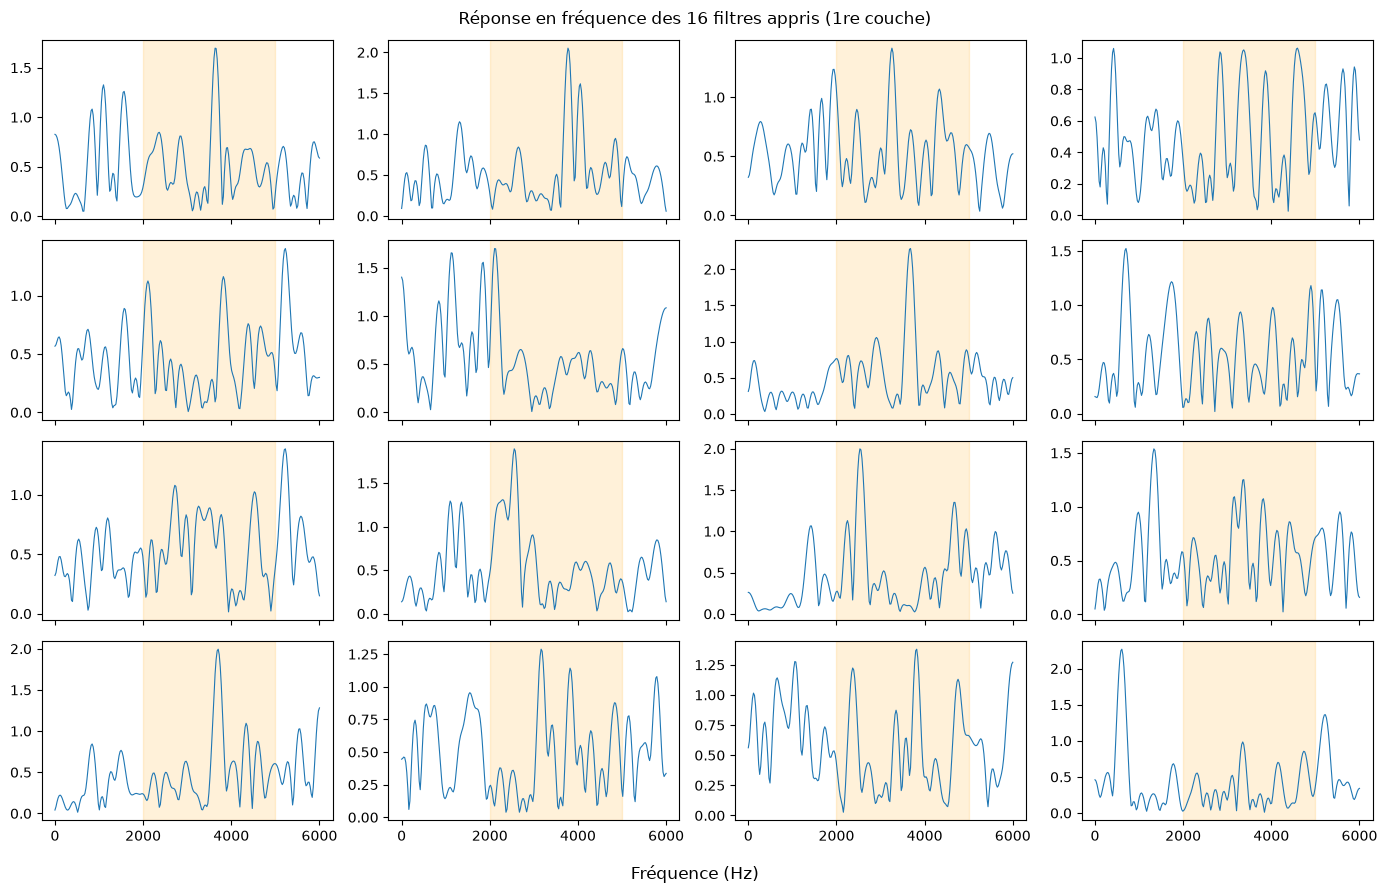

In [18]:
import matplotlib.pyplot as plt

y = meta["defaut"].map({c: i for i, c in enumerate(ORDRE_LOC)}).to_numpy()
modele = entrainer_cnn(X, y, n_classes=4, epoques=8, graine=0)

filtres = modele.extracteur[0][0].weight.detach().numpy()[:, 0, :]   # (16 filtres, 64 points)
freqs = np.fft.rfftfreq(512, d=1 / 12000)                            # axe des fréquences (Hz)

fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharex=True)
for f, ax in zip(filtres, axes.ravel()):
    reponse = np.abs(np.fft.rfft(f, n=512))      # gain du filtre à chaque fréquence
    ax.plot(freqs, reponse, lw=0.8)
    ax.axvspan(2000, 5000, color="orange", alpha=0.15)   # votre bande d'enveloppe, pour comparer
fig.supxlabel("Fréquence (Hz)")
fig.suptitle("Réponse en fréquence des 16 filtres appris (1re couche)")
plt.tight_layout(); 
fig.savefig("../images/cnn_filtres.png", dpi=150, bbox_inches="tight")
plt.show()

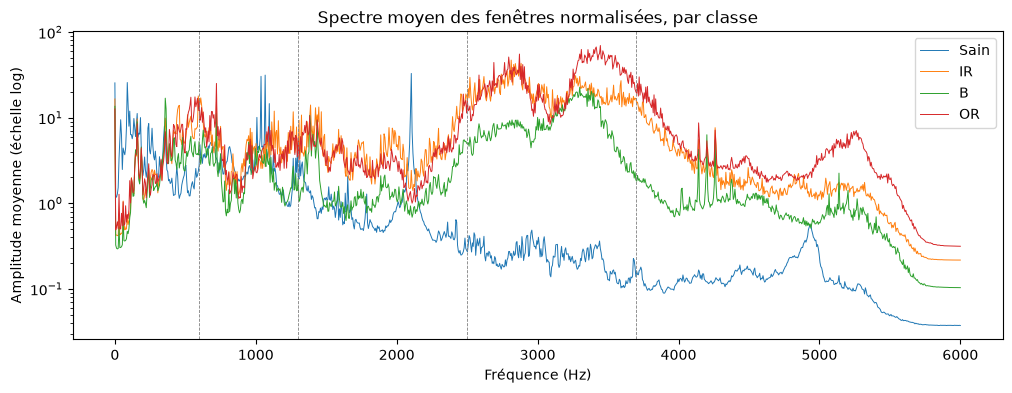

In [19]:
freqs_x = np.fft.rfftfreq(X.shape[1], d=1 / 12000)
classes = meta["defaut"].to_numpy()

plt.figure(figsize=(12, 4))
for c in ORDRE_LOC:
    spectre = np.abs(np.fft.rfft(X[classes == c], axis=1)).mean(axis=0)   # spectre moyen de la classe
    plt.semilogy(freqs_x, spectre, lw=0.7, label=c)
for f in (600, 1300, 2500, 3700):                                          # bandes vues par le CNN
    plt.axvline(f, color="grey", ls="--", lw=0.6)
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Amplitude moyenne (échelle log)")
plt.title("Spectre moyen des fenêtres normalisées, par classe")
plt.legend(); 
plt.savefig("../images/cnn_spectre_classes.png", dpi=150, bbox_inches="tight")
plt.show()

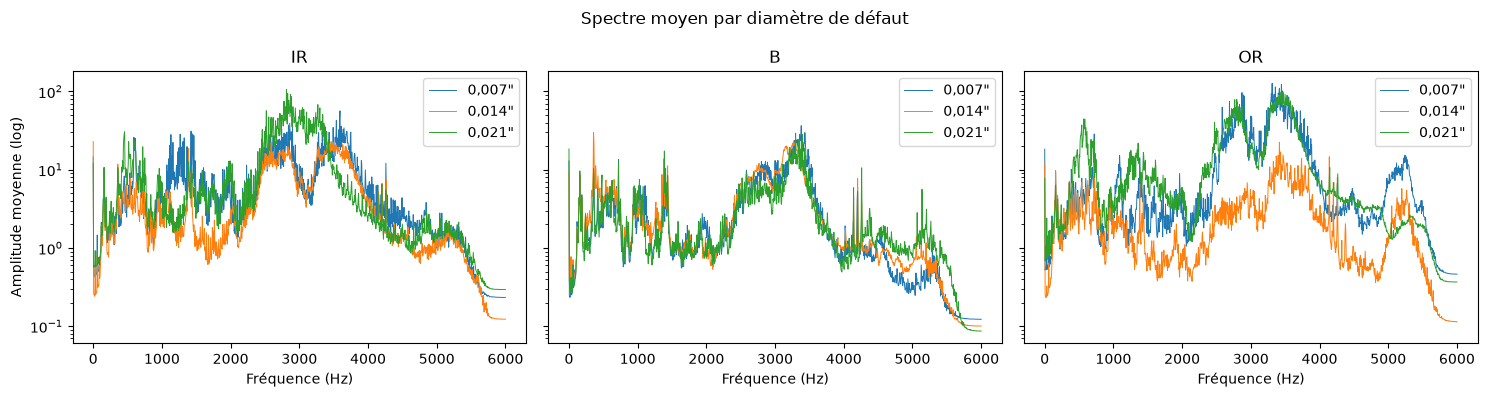

In [20]:
diametres = meta["diametre_mils"].to_numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, ["IR", "B", "OR"]):
    for d in (7, 14, 21):
        masque = (classes == c) & (diametres == d)
        spectre = np.abs(np.fft.rfft(X[masque], axis=1)).mean(axis=0)
        ax.semilogy(freqs_x, spectre, lw=0.7, label=f'0,0{d:02d}"')
    ax.set_title(c); ax.set_xlabel("Fréquence (Hz)"); ax.legend()
axes[0].set_ylabel("Amplitude moyenne (log)")
fig.suptitle("Spectre moyen par diamètre de défaut")
plt.tight_layout(); 
fig.savefig("../images/cnn_spectre_diametres.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
diam = meta["diametre_mils"].to_numpy()
app, test = diam != 14, diam == 14          # le sain reste en apprentissage

modele = entrainer_cnn(X[app], y[app], n_classes=4, epoques=8, graine=0)
pred = predire(modele, X[test])

predit = pd.Series(np.array(ORDRE_LOC)[pred], index=meta.index[test], name="prédit")
print(pd.crosstab(meta.loc[test, "fichier"], predit))

prédit              B
fichier              
12kDE_B014_L0      59
12kDE_B014_L1      59
12kDE_B014_L2      59
12kDE_B014_L3      59
12kDE_IR014_L0     59
12kDE_IR014_L1     59
12kDE_IR014_L2     59
12kDE_IR014_L3     59
12kDE_OR014at6_L0  59
12kDE_OR014at6_L1  59
12kDE_OR014at6_L2  59
12kDE_OR014at6_L3  59


In [15]:
pred_app = predire(modele, X[app])
predit_app = pd.Series(np.array(ORDRE_LOC)[pred_app], index=meta.index[app], name="prédit")
print(pd.crosstab(meta.loc[app, "defaut"], predit_app))

prédit    B   IR   OR  Sain
defaut                     
B       472    0    0     0
IR        0  473    0     0
OR        0    0  472     0
Sain      0    0    0   828


In [16]:
modele.eval()
with torch.no_grad():
    proba = torch.softmax(modele(torch.from_numpy(X[test])), dim=1).numpy()

print(pd.DataFrame(proba, columns=ORDRE_LOC, index=meta.loc[test, "fichier"])
        .groupby(level=0).mean().round(2))       # probabilité moyenne par enregistrement

                   Sain    IR     B    OR
fichier                                  
12kDE_B014_L0      0.00  0.01  0.99  0.00
12kDE_B014_L1      0.00  0.00  0.99  0.00
12kDE_B014_L2      0.00  0.01  0.99  0.00
12kDE_B014_L3      0.00  0.01  0.98  0.01
12kDE_IR014_L0     0.03  0.24  0.69  0.03
12kDE_IR014_L1     0.01  0.04  0.93  0.02
12kDE_IR014_L2     0.01  0.02  0.96  0.01
12kDE_IR014_L3     0.00  0.01  0.98  0.01
12kDE_OR014at6_L0  0.00  0.00  0.99  0.00
12kDE_OR014at6_L1  0.00  0.00  0.99  0.00
12kDE_OR014at6_L2  0.00  0.00  0.99  0.00
12kDE_OR014at6_L3  0.00  0.01  0.98  0.01
